# 02 · Null model: variance decomposition

In step-up selection for multilevel models, the null model has only an intercept in the fixed part and partitions the response variance into model components (Raudenbush & Bryk, 2002). Weekly observations are nested within store × product pairs, and the pairs belong to two crossed groupings, store and product (Baayen et al., 2008). The models were fitted on the first 104 weeks of training data (D11, revised).

Both language versions of the notebook read the same run, saved by `scripts/fit_null_models.py` in `outputs/runs/null_models`.

*Data: dunnhumby Source Files – Breakfast at the Frat.*

In [1]:
LANG = "en"

In [2]:
import warnings

import pandas as pd
from IPython.display import display

from retail_multilevel import viz
from retail_multilevel.i18n import t
from retail_multilevel.paths import PROCESSED_DIR
from retail_multilevel.runs import load_run

warnings.filterwarnings("ignore", category=FutureWarning)
viz.use_retina()
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", "{:,.4f}".format)
run = load_run("null_models", "20261124-114105-b15be79c")
print(t("data_credit", LANG))
print("run:", run.run_id, "| finished_at:", run.metadata["finished_at"])
sample = run.load_json("sample")
display(pd.Series(sample).to_frame("training sample"))

Data: dunnhumby Source Files – Breakfast at the Frat
run: 20261124-114105-b15be79c | finished_at: 2026-11-24T11:41:55.743542


,training sample
nobs,347092
n_stores,77
n_products,55
n_pairs,3859
first_week,2009-01-14 00:00:00
last_week,2011-01-05 00:00:00


The run identifier and finish time are shown above. The training sample has 347,092 rows, 77 stores, 55 products and 3,859 pairs, from 2009-01-14 to 2011-01-05.

## 1. Models M0 to M4

The five models were fitted by REML (Bates et al., 2015). Their REML likelihoods are comparable because each has only an intercept in the fixed part (Pinheiro & Bates, 2000). M0 is a single-level regression (OLS). M1 has a store random effect and M2 a product random effect. M3 includes both, and M4 adds the store × product interaction (the pair).

In [3]:
fits = run.load_table("fits")
display(fits[["name", "formula"]])

,name,formula
0,M0_ols,LOG_UNITS ~ 1
1,M1_store,LOG_UNITS ~ 1 + (1 | STORE_NUM)
2,M2_product,LOG_UNITS ~ 1 + (1 | UPC)
3,M3_crossed,LOG_UNITS ~ 1 + (1 | STORE_NUM) + (1 | UPC)
4,M4_crossed_pair,LOG_UNITS ~ 1 + (1 | STORE_NUM) + (1 | UPC) + (1 | STORE_NUM:UPC)


## 2. Fit statistics

The table gives the number of parameters, the REML log-likelihood, the AIC, the BIC, the fitting time and the number of convergence messages.

In [4]:
display(fits[["name", "npar", "loglik", "aic", "bic", "seconds", "n_messages"]])

,name,npar,loglik,aic,bic,seconds,n_messages
0,M0_ols,2,"-563,134.7198","1,126,273.4395","1,126,294.9542",0.0418,0
1,M1_store,3,"-551,362.1665","1,102,730.3330","1,102,762.6050",1.6540,0
2,M2_product,3,"-431,259.3269","862,524.6537","862,556.9258",1.6754,0
3,M3_crossed,4,"-389,928.2579","779,864.5158","779,907.5452",6.7715,0
4,M4_crossed_pair,5,"-346,786.4831","693,582.9663","693,636.7530",29.0096,0


The log-likelihood rises from −563,135 (M0) to −346,786 (M4). AIC drops from 1,126,273 to 693,583, and both AIC and BIC decrease with each added model. No fit produced convergence messages. M4 took about 29 seconds.

## 3. Likelihood-ratio tests

Each test compares a restricted model with the full model, which has one more variance component. Under the null hypothesis that component is zero, that is, on the **boundary** of the parameter space (σ² = 0), and the statistic does not follow a χ² with 1 degree of freedom. The reference distribution is a 50:50 mixture of χ²₀ and χ²₁ (Self & Liang, 1987; Stram & Lee, 1994), so `p_value` is half of `p_naive`.

In [5]:
lr = run.load_table("lr")


def format_p(p):
    return "< 1e-300" if p < 1e-300 else f"{p:.2e}"


display(lr.assign(p_value=lr["p_value"].map(format_p), p_naive=lr["p_naive"].map(format_p)))

,restricted,full,stat,df,p_value,p_naive
0,M0_ols,M1_store,"23,545.1065",1,< 1e-300,< 1e-300
1,M0_ols,M2_product,"263,750.7858",1,< 1e-300,< 1e-300
2,M1_store,M3_crossed,"322,867.8172",1,< 1e-300,< 1e-300
3,M2_product,M3_crossed,"82,662.1380",1,< 1e-300,< 1e-300
4,M3_crossed,M4_crossed_pair,"86,283.5495",1,< 1e-300,< 1e-300


The statistics range from 23,545 (M0 versus M1) to 322,868 (M1 versus M3), with p-values below 1e-300 in every comparison. The tests provide evidence for store, product and store × product variance components. With 347,092 training rows, even small components can be detected. The M4 decomposition quantifies each component's share.

## 4. Intraclass correlation (ICC)

The chart shows the log(units) variance components for each model from M1 to M4 (Raudenbush & Bryk, 2002). The shares sum to 1 within each model.

,model,group,variance,share
0,M4_crossed_pair,STORE_NUM:UPC,0.1431,0.0849
1,M4_crossed_pair,STORE_NUM,0.1623,0.0963
2,M4_crossed_pair,UPC,0.9646,0.5724
3,M4_crossed_pair,Residual,0.4151,0.2463


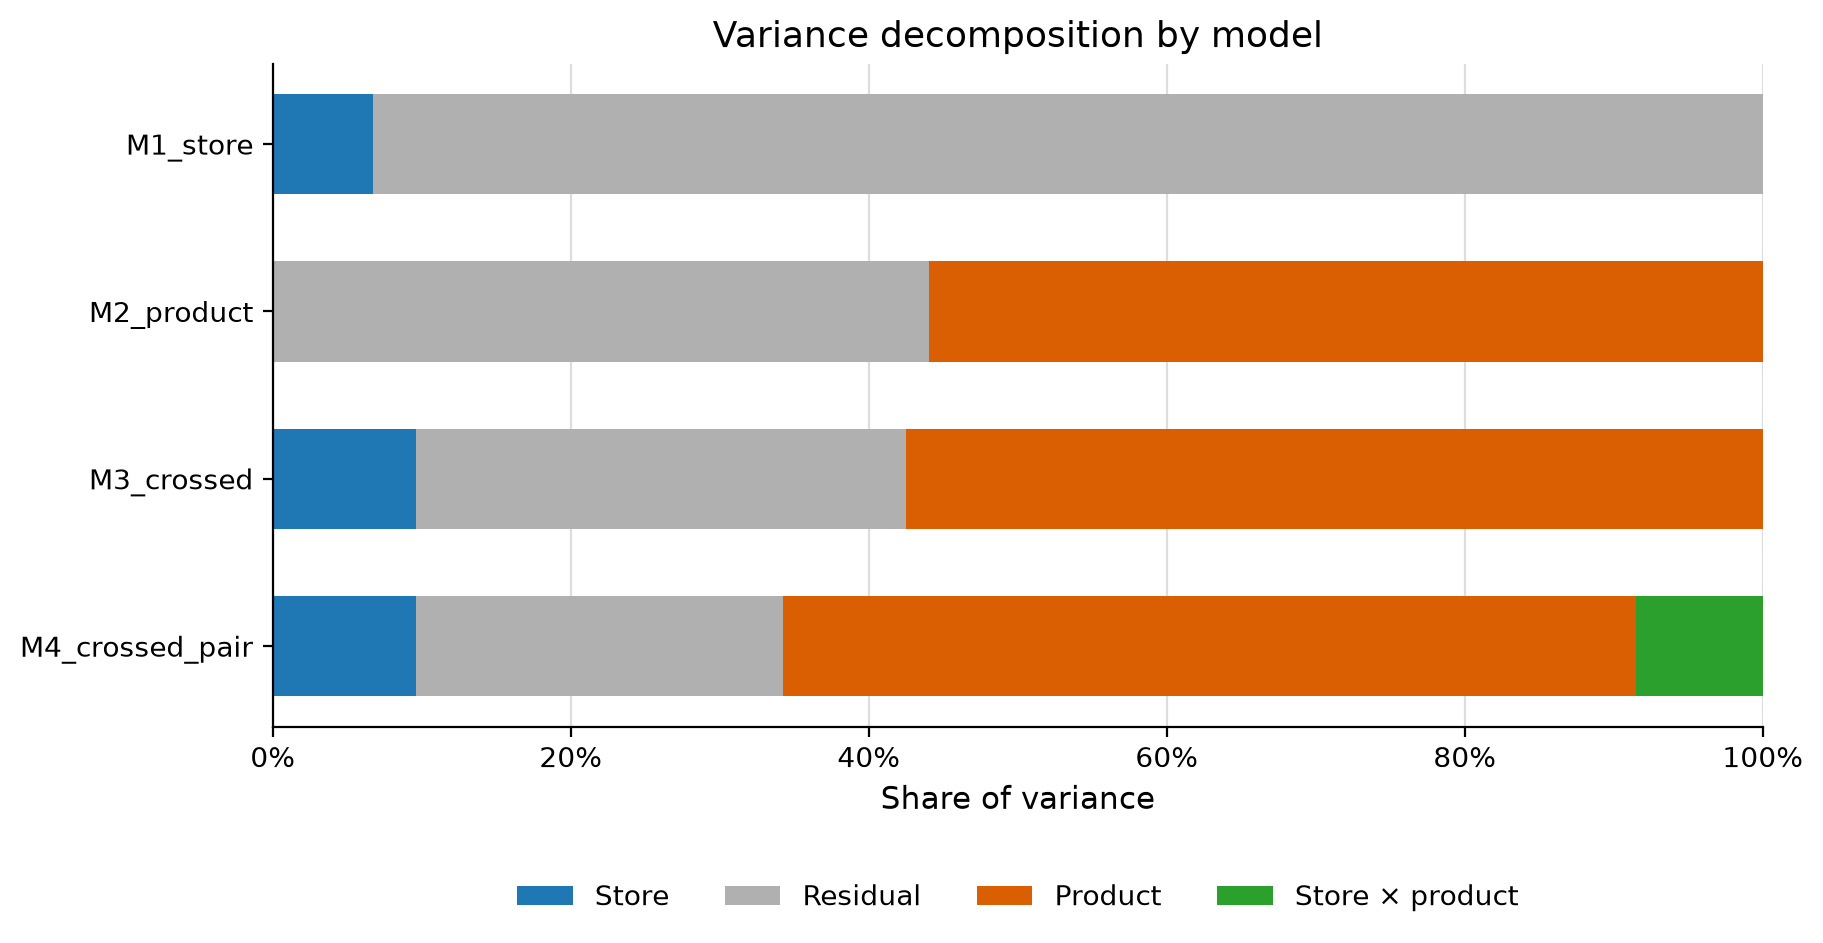

In [6]:
icc = run.load_table("icc")
fig = viz.plot_icc_by_model(icc, LANG)
icc4 = icc[icc["model"] == "M4_crossed_pair"].reset_index(drop=True)
display(icc4)

In [7]:
share = icc4.set_index("group")["share"]
derived = pd.Series(
    {
        t("corr_same_pair", LANG): share[["STORE_NUM", "UPC", "STORE_NUM:UPC"]].sum(),
        t("corr_same_store", LANG): share["STORE_NUM"],
    }
)
derived.to_frame("correlation")

,correlation
Correlation between two weeks of the same pair,0.7537
Correlation between two products in the same store,0.0963


In M4, the product accounts for 57.2% of the variance, the residual for 24.6%, the store for 9.6% and the store × product interaction for 8.5%. The correlation between two weeks of the same pair is (store + product + pair) / total = 75.4%, and the correlation between two different products in the same store is the store share, 9.6%.

In the null model, differences between products account for the largest share of log(units) variance. The residual, about 25% in M4, captures the week-to-week variation within a pair that the model leaves unexplained. This share is re-examined with price and promotion in notebook 03. The residual share falls from 93.3% in M1 to 24.6% in M4 as other components are added.

## 5. Predicted random effects (BLUPs) of M4

The charts show the predicted random intercept of each store and each product, with 95% intervals based on the conditional standard deviation. Products are identified by their catalogue description.

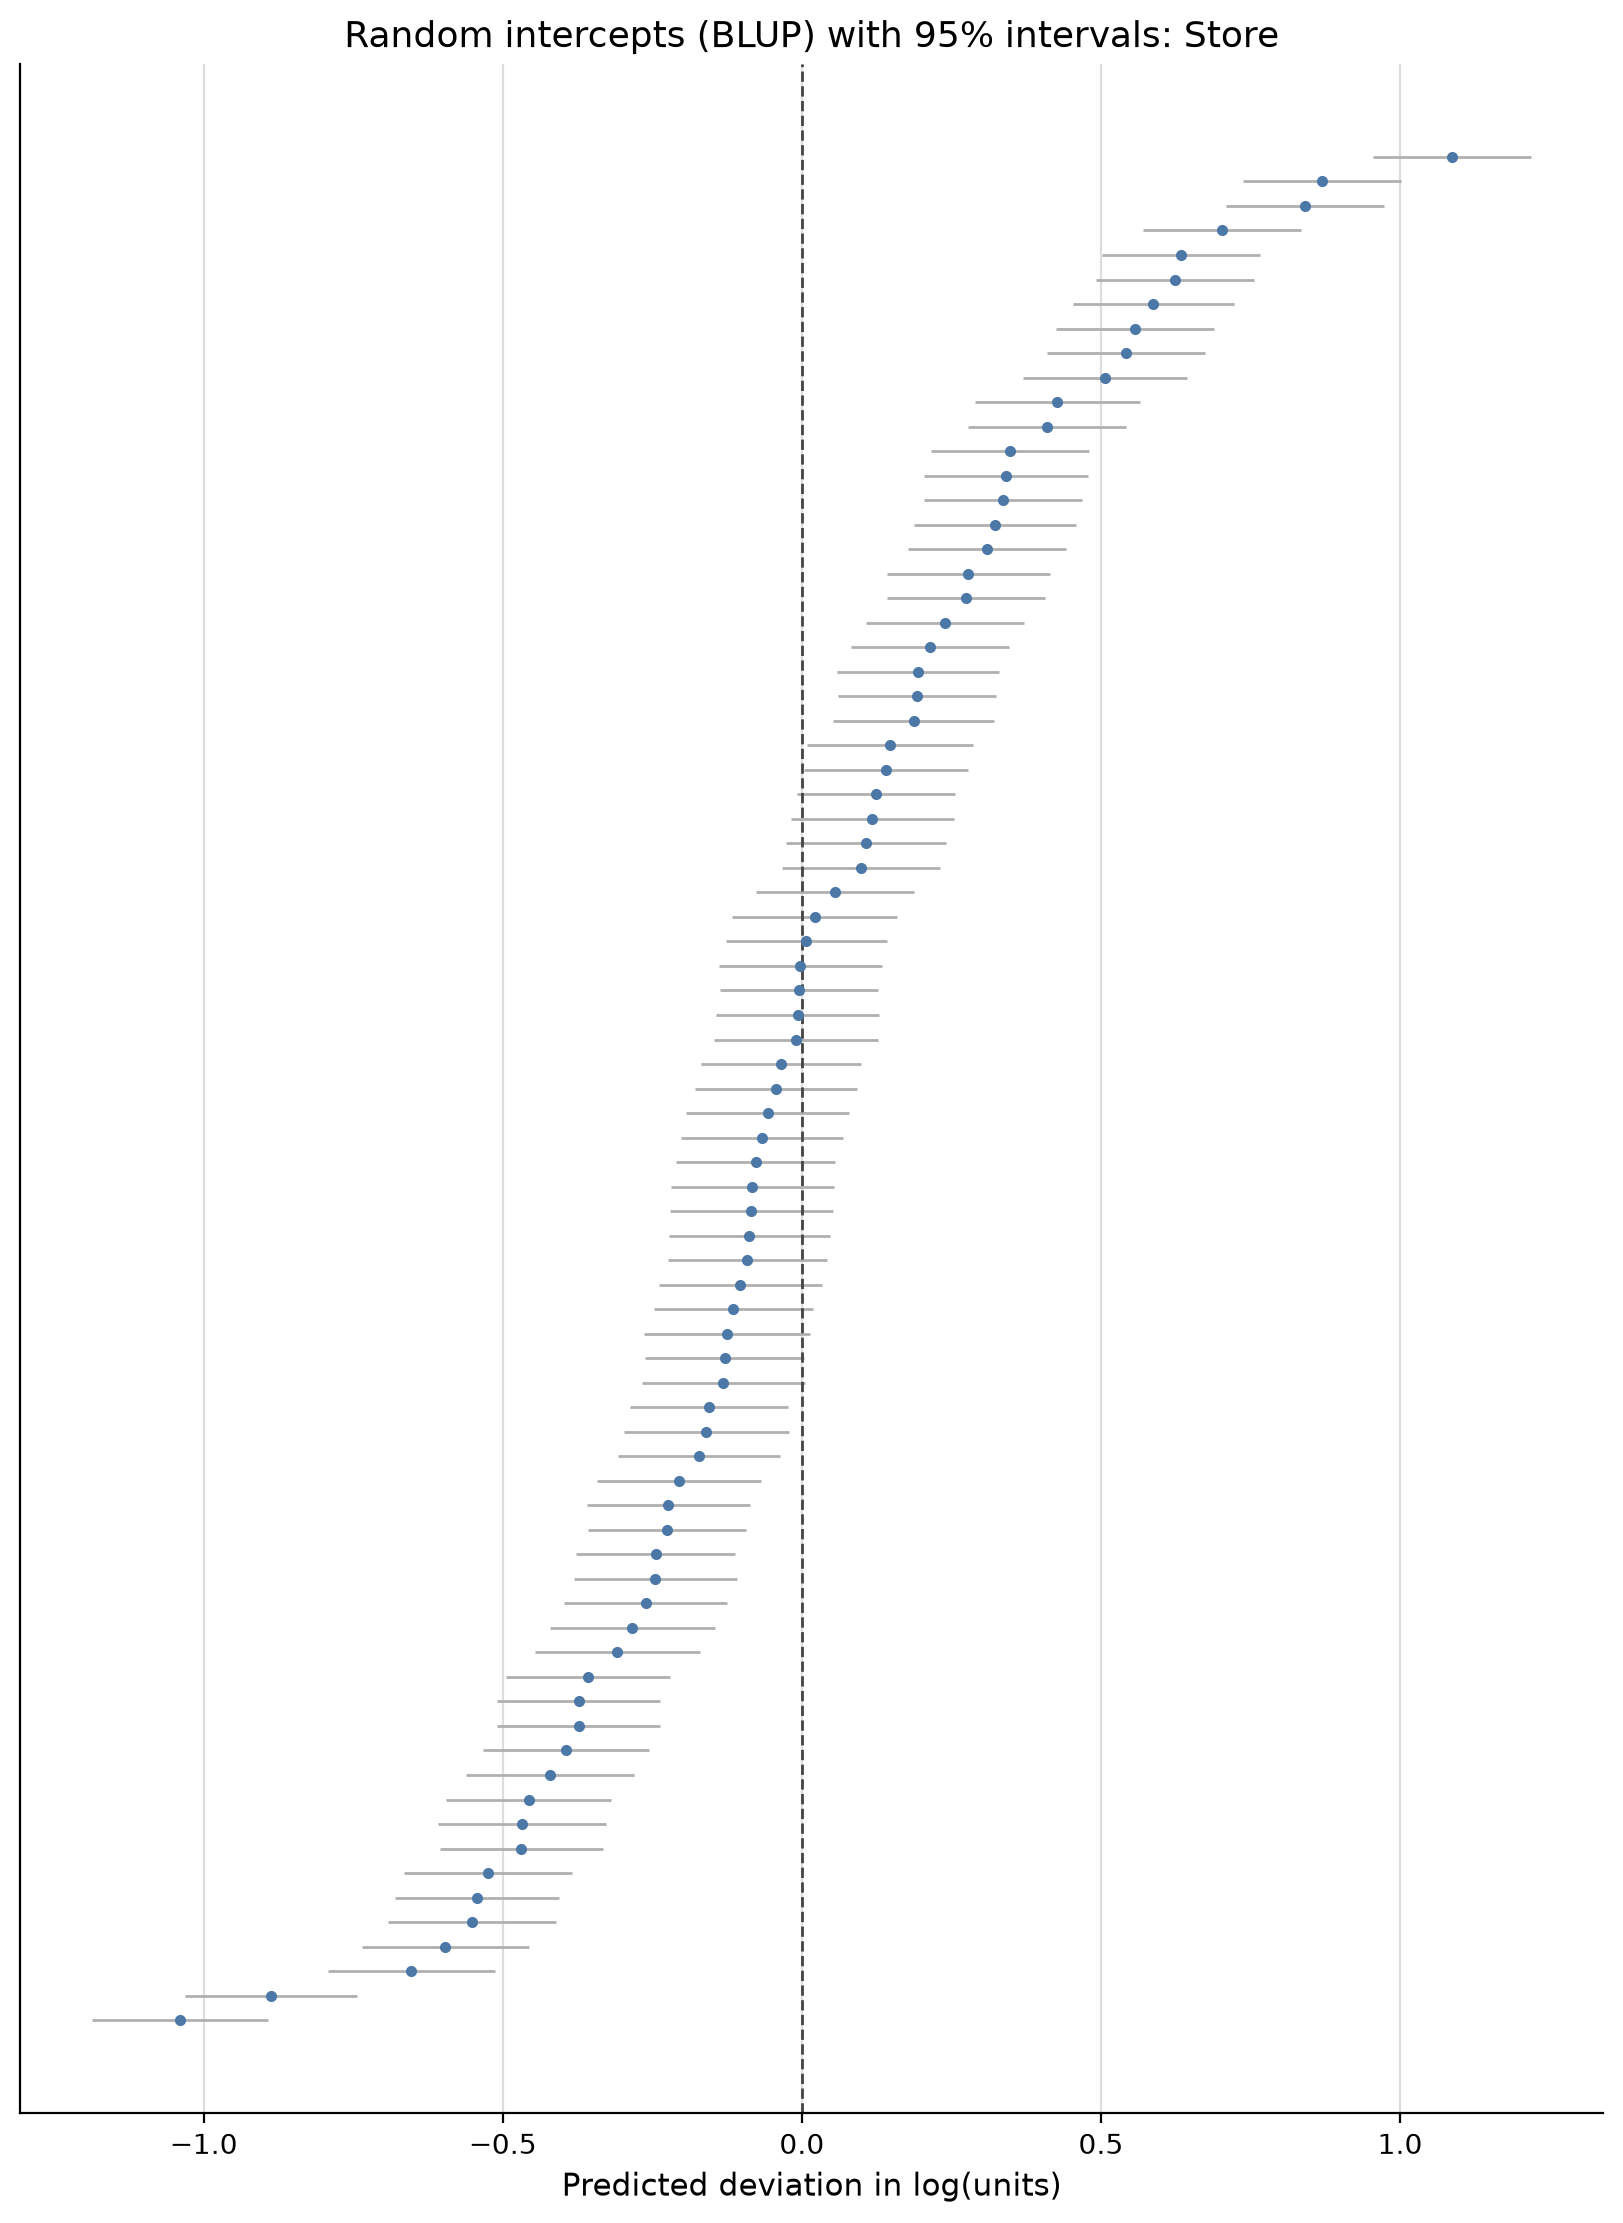

In [8]:
fig = viz.plot_caterpillar(run.load_table("ranef_store"), LANG, "STORE_NUM")

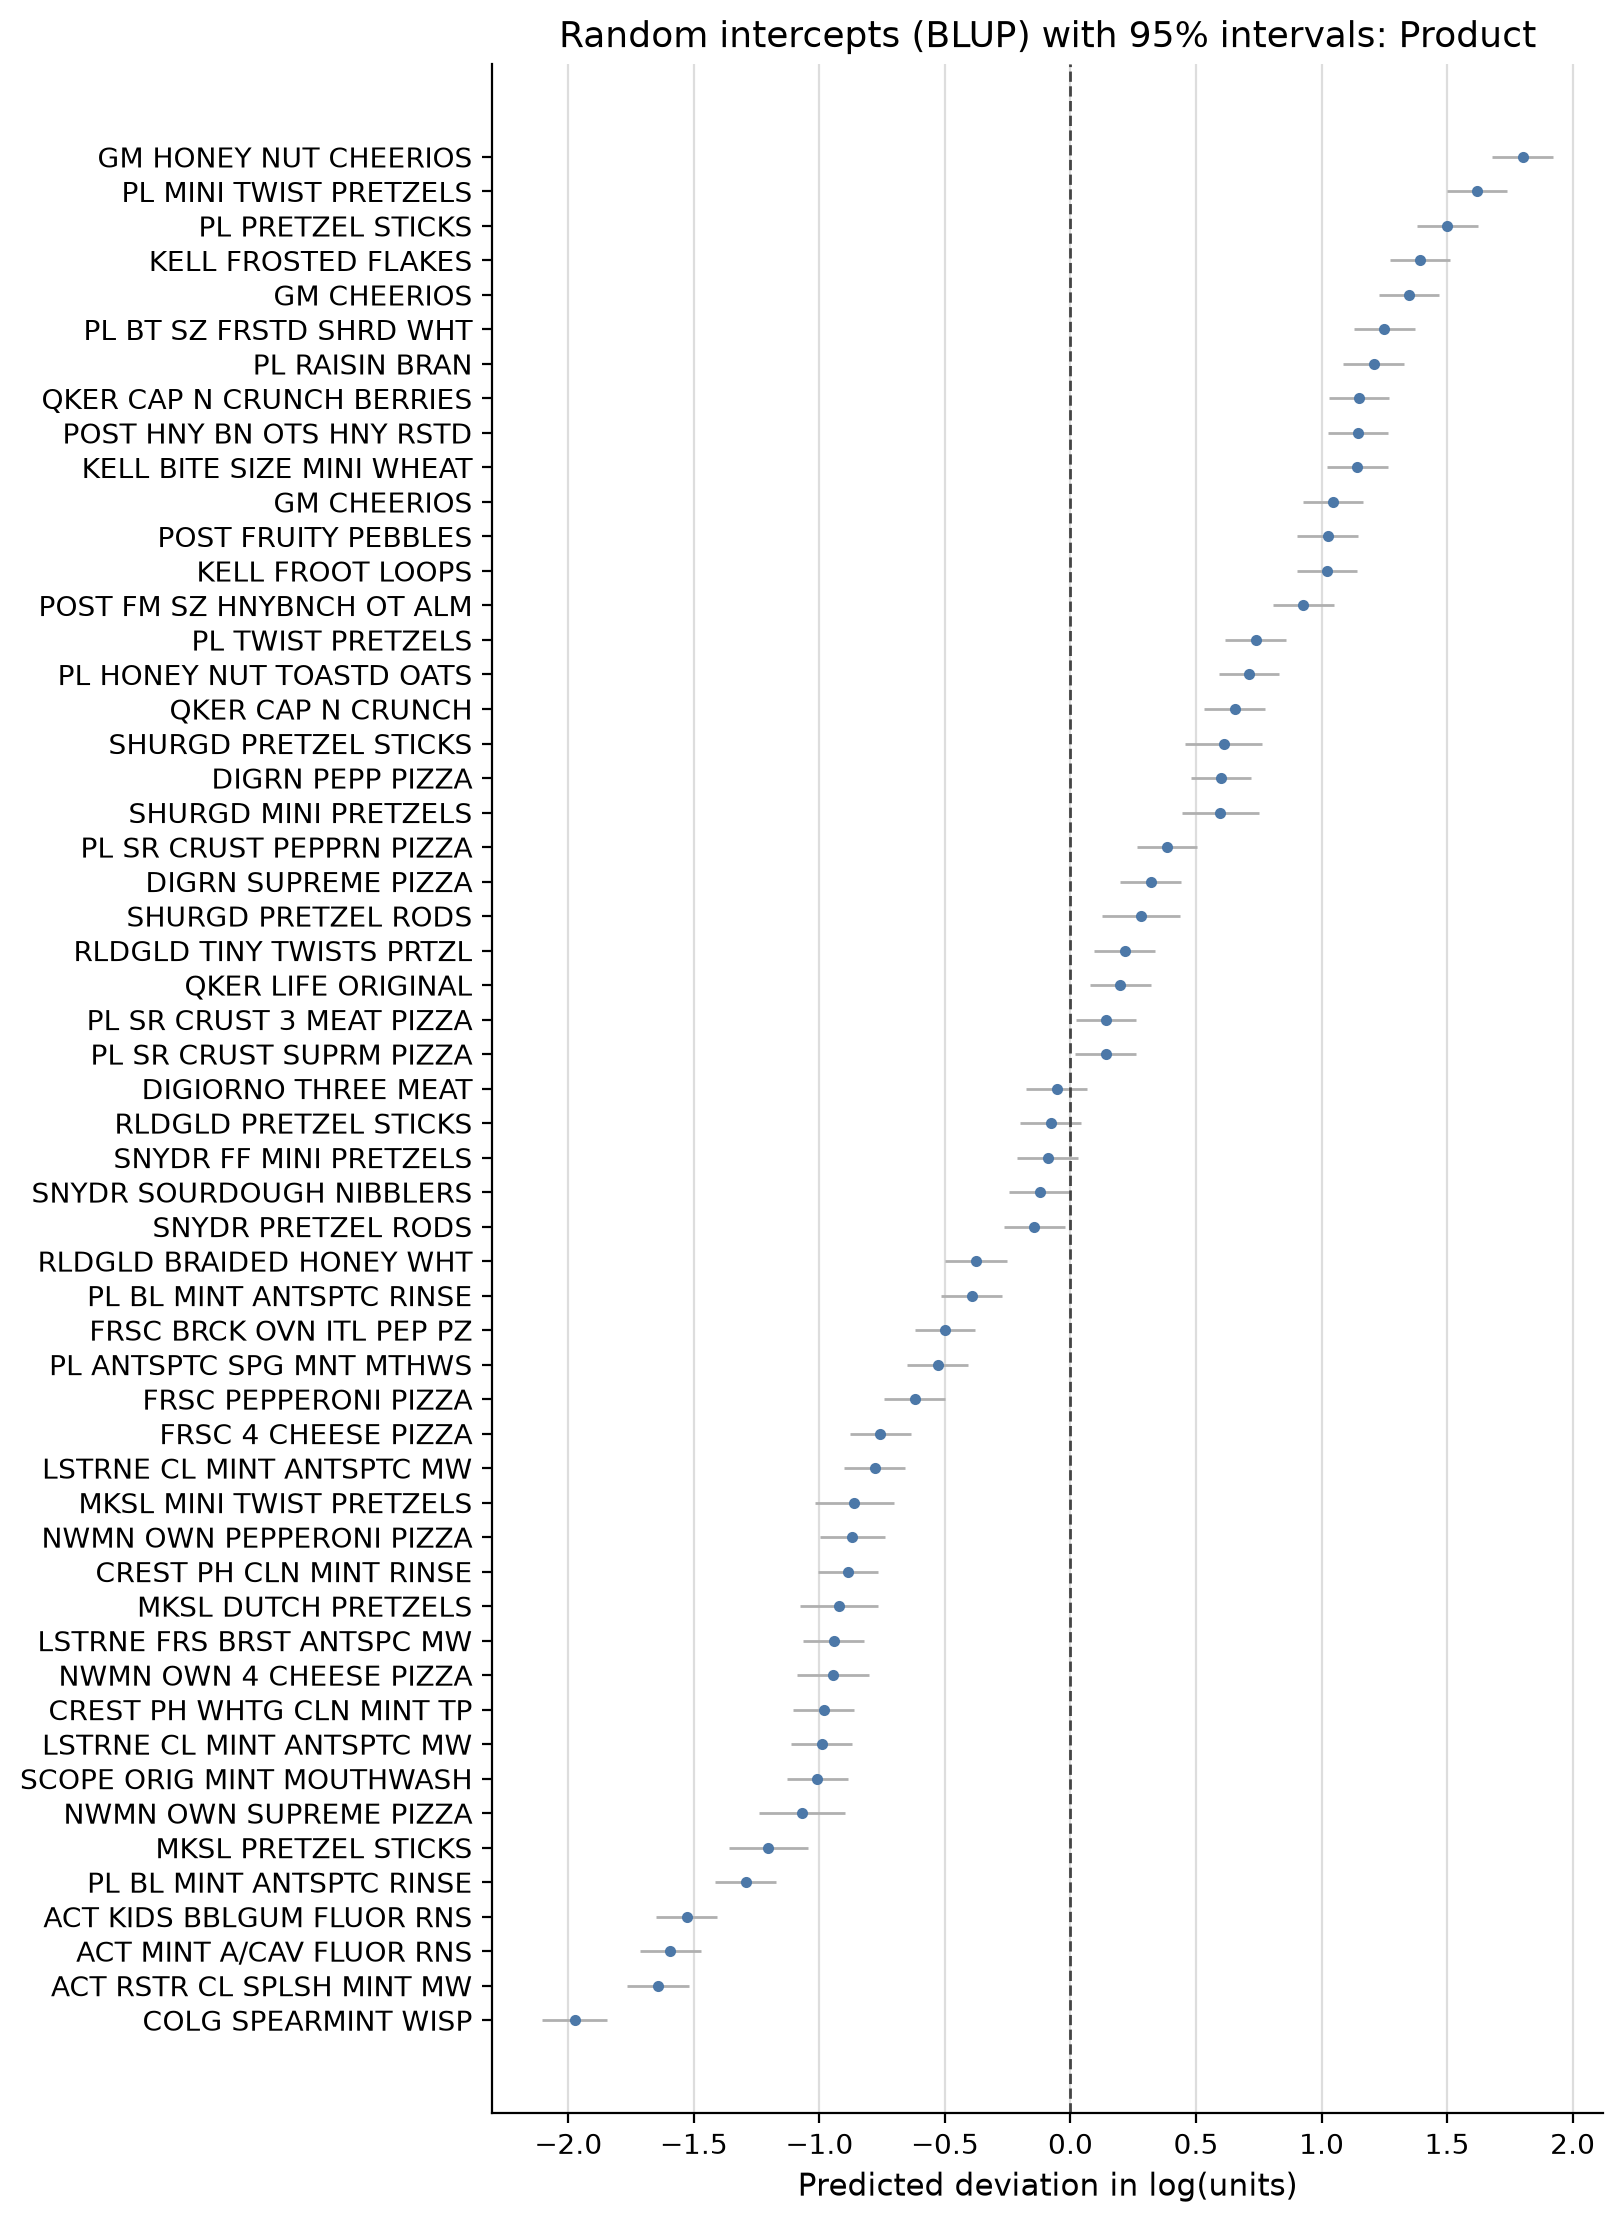

In [9]:
products = pd.read_parquet(PROCESSED_DIR / "panel.parquet", columns=["UPC", "DESCRIPTION"]).drop_duplicates("UPC")
labels = dict(zip(products["UPC"].astype(str), products["DESCRIPTION"], strict=True))
fig = viz.plot_caterpillar(run.load_table("ranef_product"), LANG, "UPC", labels=labels)

BLUPs are predicted group deviations shrunk towards the overall mean (Henderson, 1975; Robinson, 1991). As an illustration, in a random-intercept model with a single grouping factor, the observed deviation is multiplied by σ²ᵤ / (σ²ᵤ + σ²ₑ/n). The fewer observations the group has (n), the greater the shrinkage from partial pooling. In M4, the conditional standard deviations are about 0.07 for stores and 0.06 for products. The intervals are narrow relative to the spread across groups, especially across products.

## 6. Cross-check against lme4

Model M1 (random effect of store only) was also fitted with statsmodels `MixedLM` (Seabold & Perktold, 2010), an independent implementation in Python, and compared with lme4 (R; Bates et al., 2015).

In [10]:
display(run.load_table("crosscheck"))

,component,statsmodels,lme4,rel_diff
0,STORE_NUM,0.1001,0.1007,0.0060
1,Residual,1.4020,1.4020,0.0000


The relative difference between the residual variance estimates is 1.3e-6. For the store variance, the difference is 0.6% (0.1001 versus 0.1007). `MixedLM` was used for this single-grouping check. Crossed effects in `MixedLM` require a single group with `vc_formula`. The direct syntax for crossed effects motivated the choice of lme4 for the other models (decision D1). The performance of `MixedLM` with crossed effects at this size fell outside the check.

## 7. Conclusions and next step

In M4, products account for 57.2% of log(units) variance, stores for 9.6%, the store × product interaction for 8.5% and the residual for 24.6%. The boundary-corrected likelihood-ratio tests provide evidence for each grouping component.

M4 estimates a correlation of 75.4% between two weeks of the same pair and 9.6% between different products in the same store. In the single-grouping check, lme4 and statsmodels produced similar estimates.

Notebook 03 will add the fixed effects of price and promotion. Random slopes will be studied afterwards, and their specification needs care in `MixedLM`. With `groups='g'` and `re_formula='x'`, a component `vc_formula={'h': '0 + x'}` does not create a slope per level of `h`: it generates the column `x` within each group `g`, that is, a second slope variance at the level of `g`, duplicating the one `re_formula` already estimates, and it includes no intercept per `h`. The result is unidentifiable components, which tend to fail to converge or to get zero variance. The specification per level of `h` would be `vc_formula={'h': '0 + C(h)', 'h_x': '0 + C(h):x'}`, and in lme4 it would be `(1 + x | g) + (1 + x | g:h)`. In this project, random slopes were specified directly in lme4.

## References

Baayen, R. H., Davidson, D. J., & Bates, D. M. (2008). Mixed-effects modeling with crossed random effects for subjects and items. *Journal of Memory and Language, 59*(4), 390–412. https://doi.org/10.1016/j.jml.2007.12.005

Bates, D., Mächler, M., Bolker, B., & Walker, S. (2015). Fitting linear mixed-effects models using lme4. *Journal of Statistical Software, 67*(1), 1–48. https://doi.org/10.18637/jss.v067.i01

Henderson, C. R. (1975). Best linear unbiased estimation and prediction under a selection model. *Biometrics, 31*(2), 423–447. https://doi.org/10.2307/2529430

Pinheiro, J. C., & Bates, D. M. (2000). *Mixed-effects models in S and S-PLUS*. Springer. https://doi.org/10.1007/b98882

Raudenbush, S. W., & Bryk, A. S. (2002). *Hierarchical linear models: Applications and data analysis methods* (2nd ed.). Sage. (partial verification: edition year not checked against a primary source)

Robinson, G. K. (1991). That BLUP is a good thing: The estimation of random effects. *Statistical Science, 6*(1), 15–32. https://doi.org/10.1214/ss/1177011926

Seabold, S., & Perktold, J. (2010). Statsmodels: Econometric and statistical modeling with Python. In *Proceedings of the 9th Python in Science Conference* (pp. 92–96). https://doi.org/10.25080/Majora-92bf1922-011

Self, S. G., & Liang, K.-Y. (1987). Asymptotic properties of maximum likelihood estimators and likelihood ratio tests under nonstandard conditions. *Journal of the American Statistical Association, 82*(398), 605–610. https://doi.org/10.1080/01621459.1987.10478472

Stram, D. O., & Lee, J. W. (1994). Variance components testing in the longitudinal mixed effects model. *Biometrics, 50*(4), 1171–1177. https://doi.org/10.2307/2533455